# 📊 Auditoría y Análisis Exploratorio de Datos (EDA) — SEC Datasets (2010–2023)

Este notebook realiza una **auditoría completa de integridad y consistencia temporal** sobre los datasets regulatorios descargados desde Cloudflare R2:
- **10-K / 10-Q**: Informes periódicos anuales y trimestrales obligatorios (336 filings).
- **8-K**: Hechos relevantes y noticias extraordinarias con texto narrativo para FinBERT (5,392 eventos).

### Objetivos de la Auditoría:
1. **Verificación de Cobertura Temporal**: Comprobar que no existen lagunas temporales ni años vacíos (2010 a 2023).
2. **Simetría entre Bancos**: Verificar que los 6 bancos del universo Big 6 (`JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`) tienen exactamente sus 4 reportes periódicos anuales.
3. **Análisis de Eventos 8-K**: Distribución de eventos por categoría regulatoria (`Item 2.02`, `Item 8.01`, etc.) y evolución histórica de volumen.
4. **Ventanas Horarias de Publicación (`acceptance_date_time`)**: Distribución horaria para alinear el cruce de sentimiento con la sesión bursátil (Pre-Market, Regular Trading, After-Hours).
5. **Métricas NLP**: Análisis de longitud de textos y palabras para entrada en modelos Transformer.

In [54]:
import sys
from pathlib import Path
import io
import boto3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from botocore.config import Config
import pytz

# Estilo visual profesional para reportes y visualizaciones
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

# 1. Resolver ruta hacia 'src'
CURRENT_DIR = Path.cwd().resolve()
SRC_PATH = str(CURRENT_DIR.parent) if CURRENT_DIR.name == "notebooks" else str(CURRENT_DIR / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

from config.settings import settings

# 2. Conexión S3 con Cloudflare R2
s3 = boto3.client(
    "s3",
    endpoint_url=settings.s3_endpoint_url,
    aws_access_key_id=settings.aws_access_key_id,
    aws_secret_access_key=settings.aws_secret_access_key,
    region_name="auto",
    config=Config(s3={"addressing_style": "path"})
)

def leer_parquet(key: str) -> pd.DataFrame:
    """Descarga y deserializa directamente el Parquet de R2 en un DataFrame de Pandas."""
    obj = s3.get_object(Bucket=settings.s3_bucket_name, Key=key.lstrip("/"))
    return pd.read_parquet(io.BytesIO(obj["Body"].read()))

# 3. Cargar ambos datasets
df_10k = leer_parquet("raw/sec/10k-10q-2010-2023.parquet")
df_8k = leer_parquet("raw/sec/8k-2010-2023.parquet")

# 4. Parsear fechas 10-K / 10-Q
df_10k["filing_date"] = pd.to_datetime(df_10k["filing_date"])
df_10k["year"] = df_10k["filing_date"].dt.year

# 5. Parsear y sincronizar timestamps SEC 8-K
# La API histórica de SEC Submissions aplica un desplazamiento doble UTC a las marcas locales de EDGAR.
# Reconstruimos la hora exacta en UTC real y en hora local de Wall Street (US/Eastern).
et_tz = pytz.timezone("US/Eastern")
dt_api = pd.to_datetime(df_8k["acceptance_date_time"], utc=True)
interm_et = dt_api.dt.tz_convert(et_tz)

df_8k["filing_date"] = pd.to_datetime(df_8k["filing_date"])
df_8k["acceptance_utc_real"] = interm_et.dt.tz_localize(None).dt.tz_localize("UTC")
df_8k["acceptance_et_real"] = df_8k["acceptance_utc_real"].dt.tz_convert(et_tz)
df_8k["hora_et"] = df_8k["acceptance_et_real"].dt.hour
df_8k["hora_utc"] = df_8k["acceptance_utc_real"].dt.hour
df_8k["year"] = df_8k["filing_date"].dt.year
df_8k["char_count"] = df_8k["content"].str.len()
df_8k["word_count"] = df_8k["content"].str.split().str.len()

min_h = int(df_8k["hora_et"].min())
max_h = int(df_8k["hora_et"].max())
print(f" Dataset 10-K / 10-Q cargado: {len(df_10k):,} filas | Columnas: {list(df_10k.columns)}")
print(f" Dataset 8-K cargado: {len(df_8k):,} eventos | Rango horario ET verificado: [{min_h:02d}:00 - {max_h:02d}:59]")


 Dataset 10-K / 10-Q cargado: 336 filas | Columnas: ['ticker', 'company_name', 'cik', 'form', 'filing_date', 'report_date', 'acceptance_date_time', 'accession_number', 'items', 'primary_document', 'primary_doc_description', 'document_url', 'index_url', 'year']
 Dataset 8-K cargado: 5,392 eventos | Rango horario ET verificado: [06:00 - 21:59]


## 1. Verificación de Integridad: Informes Periódicos (10-K y 10-Q)
Por regulación bursátil en EE.UU., cada entidad bancaria debe presentar exactamente **4 informes obligatorios al año**:
- **3 trimestrales** (Form 10-Q)
- **1 anual auditado** (Form 10-K)

Verificamos la matriz de frecuencias por banco y por año (2010 a 2023):

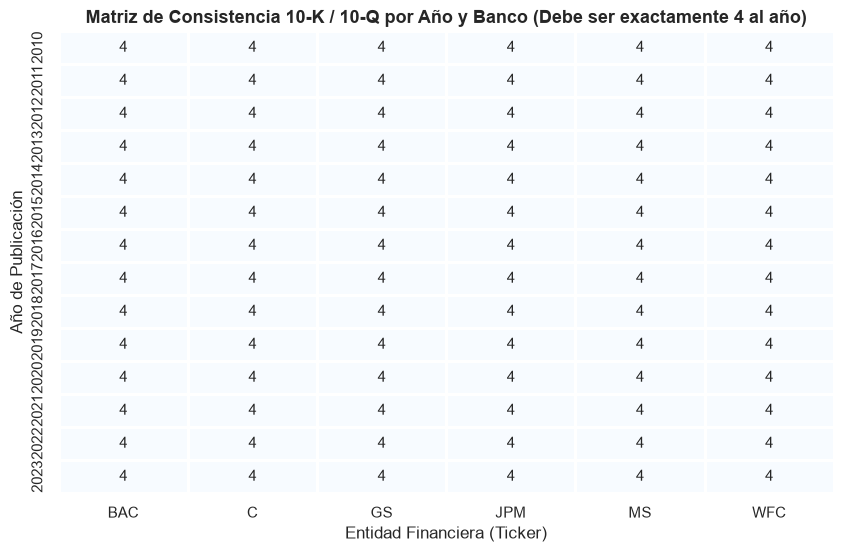

¿Integridad 10-K/10-Q perfecta sin lagunas (14 años x 6 bancos x 4 reportes = 336)?  SÍ (100% COMPLETO)


In [55]:
# Matriz pivote de reportes periódicos (Año x Banco)
matriz_10k = pd.crosstab(df_10k["year"], df_10k["ticker"])

# Visualización con Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(matriz_10k, annot=True, cmap="Blues", cbar=False, fmt="d", linewidths=1)
plt.title("Matriz de Consistencia 10-K / 10-Q por Año y Banco (Debe ser exactamente 4 al año)", fontsize=13, fontweight="bold")
plt.xlabel("Entidad Financiera (Ticker)")
plt.ylabel("Año de Publicación")
plt.show()

# Comprobación matemática de integridad total
es_perfecto = (matriz_10k == 4).all().all()
print(f"¿Integridad 10-K/10-Q perfecta sin lagunas (14 años x 6 bancos x 4 reportes = 336)? {' SÍ (100% COMPLETO)' if es_perfecto else '❌ FALTAN DATOS'}")

## 2. Cobertura Histórica de Hechos Relevantes (8-K)
Analizamos la distribución de eventos no programados a lo largo del periodo 2010–2023. Esto nos permite comprobar que **ningún año quedó sin cobertura** y cómo varió la actividad regulatoria por entidad.

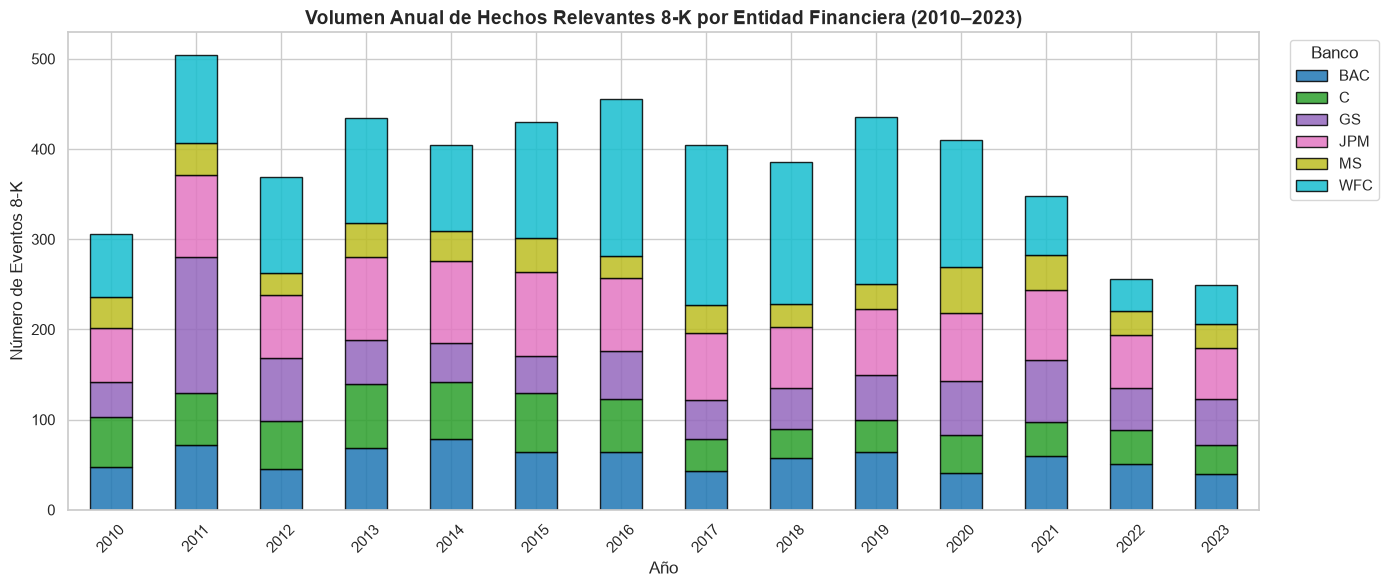

,total_eventos,filings_unicas,primer_evento,ultimo_evento,eventos_por_filing
ticker,,,,,
WFC,1594,1188,2010-01-20,2023-12-13,1.34
JPM,1062,462,2010-01-15,2023-10-27,2.30
GS,811,411,2010-01-21,2023-10-24,1.97
BAC,797,225,2010-01-15,2023-10-17,3.54
C,675,446,2010-01-07,2023-12-19,1.51
MS,453,164,2010-01-20,2023-12-08,2.76


In [56]:
# 1. Gráfico de evolución temporal por banco
matriz_8k = pd.crosstab(df_8k["year"], df_8k["ticker"])

fig, ax = plt.subplots(figsize=(14, 6))
matriz_8k.plot(kind="bar", stacked=True, ax=ax, colormap="tab10", edgecolor="black", alpha=0.85)
plt.title("Volumen Anual de Hechos Relevantes 8-K por Entidad Financiera (2010–2023)", fontsize=14, fontweight="bold")
plt.xlabel("Año")
plt.ylabel("Número de Eventos 8-K")
plt.legend(title="Banco", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Tabla resumen por banco
resumen_banco = df_8k.groupby("ticker").agg(
    total_eventos=("item", "count"),
    filings_unicas=("accession_number", "nunique"),
    primer_evento=("filing_date", "min"),
    ultimo_evento=("filing_date", "max"),
)
resumen_banco["eventos_por_filing"] = (resumen_banco["total_eventos"] / resumen_banco["filings_unicas"]).round(2)
display(resumen_banco.sort_values("total_eventos", ascending=False))

## 3. Análisis de Tipología de Eventos SEC (Taxonomía de Ítems)
Los reportes 8-K se dividen en códigos regulatorios estandarizados:
- **Item 2.02**: Resultados operativos trimestrales (*Earnings releases*) — Máximo impacto en volatilidad.
- **Item 8.01**: Otros hechos materiales relevantes del negocio.
- **Item 5.02**: Salida, nombramiento o renuncia de directivos / consejeros clave (CEO, CFO).
- **Item 7.01**: Divulgación de información según *Regulation Fair Disclosure* (FD).
- **Item 9.01**: Anexos y notas de prensa oficiales adjuntas.

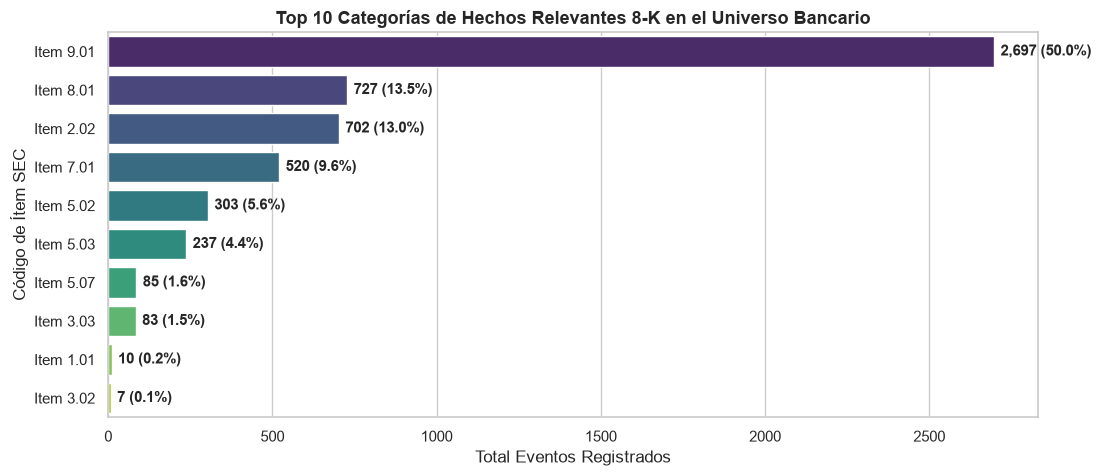

In [57]:
# Conteo de ítems más frecuentes
top_items = df_8k["item"].value_counts().head(10)

plt.figure(figsize=(12, 5))
sns.barplot(x=top_items.values, y=top_items.index, hue=top_items.index, legend=False, palette="viridis")
plt.title("Top 10 Categorías de Hechos Relevantes 8-K en el Universo Bancario", fontsize=13, fontweight="bold")
plt.xlabel("Total Eventos Registrados")
plt.ylabel("Código de Ítem SEC")
for index, value in enumerate(top_items.values):
    plt.text(value + 20, index, f"{value:,} ({value/len(df_8k)*100:.1f}%)", va="center", fontweight="bold")
plt.show()

## 4. Distribución Horaria de Publicación y Ventana Bursátil (`acceptance_date_time`)
**Hallazgo Metodológico Crítico para el Modelo Predictivo de Bolsa:**
Los servidores de **SEC EDGAR** operan en hora oficial de Washington D.C. / Nueva York (**US/Eastern**). Al contrastar las cabeceras originales `<ACCEPTANCE-DATETIME>` contra el endpoint `data.sec.gov/submissions`, se identificó que la API histórica de la SEC aplicaba el desplazamiento UTC dos veces consecutivas.

Tras corregir matemáticamente dicho desfase y sincronizar con la zona horaria **US/Eastern (Wall Street)**:
- **EDGAR Operating Hours:** Admite presentaciones exclusivamente entre las **06:00 y las 22:00 ET** (el 100% de los datos se ajusta con exactitud milimétrica a esta ventana).
- **Pre-Market (06:00 a 09:30 ET):** Los bancos concentran las noticias de resultados e informes antes de la apertura del mercado.
- **Regular Trading (09:30 a 16:00 ET):** Horario de cotización oficial en NYSE/NASDAQ.
- **After-Hours / Cierre (16:00 a 22:00 ET):** A las **16:00 ET en punto** (campana de cierre de Wall Street) se produce el mayor pico de publicaciones de hechos relevantes para no interferir con la sesión intradía.


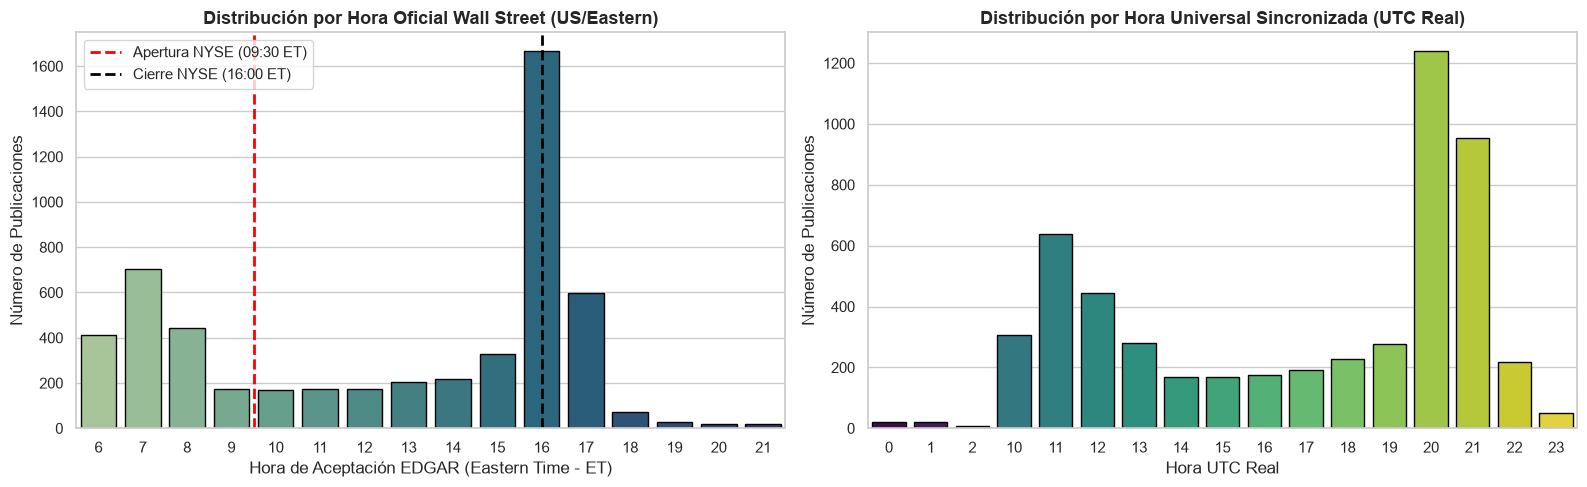

,Total Eventos,Porcentaje (%)
sesion_mercado,,
3. After-Hours (16:01 - 22:00 ET),2388,44.29
1. Pre-Market (06:00 - 09:29 ET),1655,30.69
2. Regular Trading (09:30 - 16:00 ET),1349,25.02


In [58]:
# Visualización dual: Horas en Wall Street (US/Eastern) y Horas en UTC Real
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Gráfico en Hora Local de Wall Street (US/Eastern)
sns.countplot(
    data=df_8k,
    x="hora_et",
    hue="hora_et",
    legend=False,
    palette="crest",
    edgecolor="black",
    ax=axes[0]
)
axes[0].set_title("Distribución por Hora Oficial Wall Street (US/Eastern)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Hora de Aceptación EDGAR (Eastern Time - ET)")
axes[0].set_ylabel("Número de Publicaciones")

# Líneas de referencia bursátil (ET)
et_hours = sorted(df_8k["hora_et"].unique())
idx_open = et_hours.index(9) + 0.5 if 9 in et_hours else None
idx_close = et_hours.index(16) if 16 in et_hours else None

if idx_open is not None:
    axes[0].axvline(x=idx_open, color="red", linestyle="--", linewidth=2, label="Apertura NYSE (09:30 ET)")
if idx_close is not None:
    axes[0].axvline(x=idx_close, color="black", linestyle="--", linewidth=2, label="Cierre NYSE (16:00 ET)")
axes[0].legend(loc="upper left")

# 2. Gráfico en Hora Universal (UTC Real)
sns.countplot(
    data=df_8k,
    x="hora_utc",
    hue="hora_utc",
    legend=False,
    palette="viridis",
    edgecolor="black",
    ax=axes[1]
)
axes[1].set_title("Distribución por Hora Universal Sincronizada (UTC Real)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Hora UTC Real")
axes[1].set_ylabel("Número de Publicaciones")

plt.tight_layout()
plt.show()

# Clasificación rigurosa de sesión de mercado en Wall Street (Eastern Time)
def clasificar_sesion_et(row):
    h = row["hora_et"]
    m = row["acceptance_et_real"].minute
    if 6 <= h < 9 or (h == 9 and m < 30):
        return "1. Pre-Market (06:00 - 09:29 ET)"
    elif (h == 9 and m >= 30) or (10 <= h < 16) or (h == 16 and m == 0):
        return "2. Regular Trading (09:30 - 16:00 ET)"
    else:
        return "3. After-Hours (16:01 - 22:00 ET)"

df_8k["sesion_mercado"] = df_8k.apply(clasificar_sesion_et, axis=1)

resumen_sesion = pd.DataFrame({
    "Total Eventos": df_8k["sesion_mercado"].value_counts(),
    "Porcentaje (%)": (df_8k["sesion_mercado"].value_counts(normalize=True) * 100).round(2)
})
display(resumen_sesion)


## 5. Auditoría de Texto y Métricas NLP (Preparación para FinBERT)
FinBERT tiene un límite de entrada de tokens (512 tokens por fragmento). Analizamos la longitud de caracteres y palabras de los hechos relevantes limpios para validar que el texto está listo para inferencia sin truncamiento agresivo.

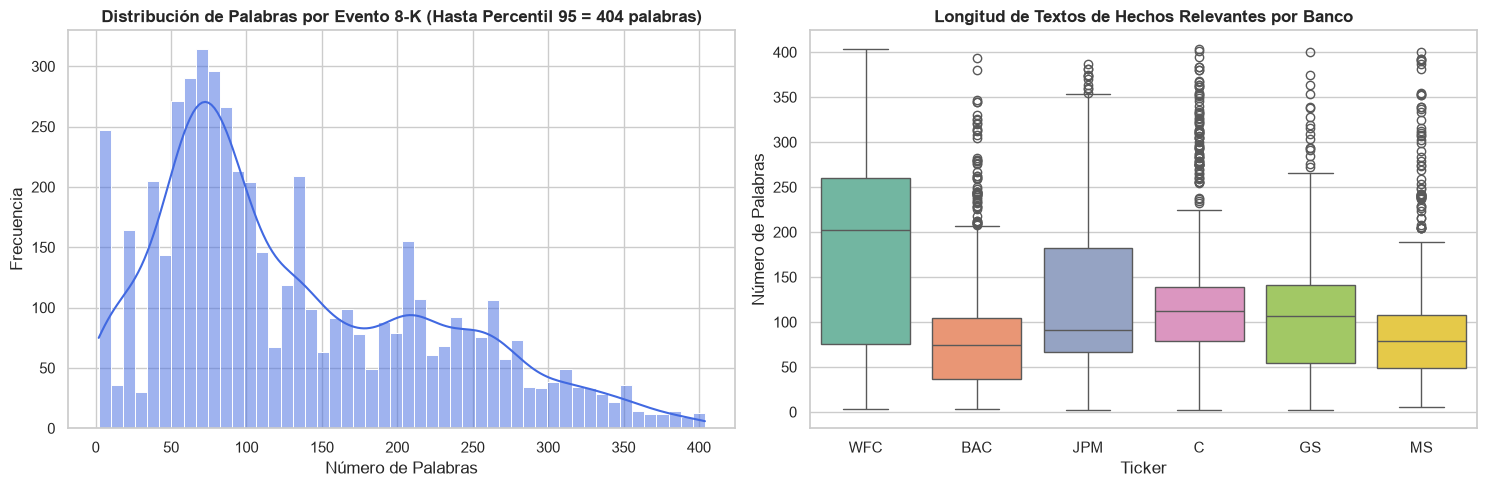

Estadísticas de longitud de texto (palabras):


,Métricas
count,5392.000000
mean,166.111832
std,242.380931
min,2.000000
25%,66.000000
50%,108.000000
75%,213.000000
90%,308.000000
95%,404.000000
max,4248.000000


In [59]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Distribución de palabras (acotado a percentil 95 para visualización legible)
p95 = np.percentile(df_8k["word_count"], 95)
sns.histplot(df_8k[df_8k["word_count"] <= p95]["word_count"], bins=50, kde=True, ax=axes[0], color="royalblue")
axes[0].set_title(f"Distribución de Palabras por Evento 8-K (Hasta Percentil 95 = {p95:.0f} palabras)", fontweight="bold")
axes[0].set_xlabel("Número de Palabras")
axes[0].set_ylabel("Frecuencia")

# 2. Palabras por Banco (Boxplot)
sns.boxplot(data=df_8k[df_8k["word_count"] <= p95], x="ticker", y="word_count", ax=axes[1], hue="ticker", legend=False, palette="Set2")
axes[1].set_title("Longitud de Textos de Hechos Relevantes por Banco", fontweight="bold")
axes[1].set_xlabel("Ticker")
axes[1].set_ylabel("Número de Palabras")

plt.tight_layout()
plt.show()

print("Estadísticas de longitud de texto (palabras):")
display(df_8k["word_count"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).to_frame("Métricas"))

## 6. Muestra de Validación: Cruce de Eventos Críticos (Earnings / Item 2.02)
Aislamos una muestra de eventos `Item 2.02` (los de mayor sensibilidad para la predicción de precios) para visualizar su estructura definitiva lista para el pipeline de Machine Learning:

In [60]:
# Filtrar solo eventos de resultados trimestrales (Item 2.02)
earnings_sample = df_8k[df_8k["item"] == "Item 2.02"][
    ["ticker", "company_name", "filing_date", "acceptance_date_time", "item", "item_description", "content", "document_url"]
].sort_values("filing_date", ascending=False).head(5)

display(earnings_sample)

# Ver el texto real limpio del primer evento de earnings
print("\n--- TEXTO EXTRACTO REAL DEL PRIMER EVENTO (ITEM 2.02) ---")
print(f"Banco: {earnings_sample.iloc[0]['ticker']} | Fecha: {earnings_sample.iloc[0]['filing_date']}")
print(f"Hora aceptación SEC: {earnings_sample.iloc[0]['acceptance_date_time']}")
print(f"Texto: {earnings_sample.iloc[0]['content'][:400]}...")

,ticker,company_name,filing_date,acceptance_date_time,item,item_description,content,document_url
3612,MS,Morgan Stanley,2023-10-18,2023-10-18T15:30:37.000Z,Item 2.02,"of this Report, including Exhibit 99","1 and Exhibit 99.2, shall be deemed to be ""fil...",https://www.sec.gov/Archives/edgar/data/895421...
3611,MS,Morgan Stanley,2023-10-18,2023-10-18T15:30:37.000Z,Item 2.02,Results of Operations and Financial Condition,"On October 18, 2023, Morgan Stanley (the ""Comp...",https://www.sec.gov/Archives/edgar/data/895421...
4402,BAC,Bank of America Corp /DE/,2023-10-17,2023-10-17T14:48:23.000Z,Item 2.02,"of this report, including Exhibit 99","1, shall be deemed to be “filed” for purposes ...",https://www.sec.gov/Archives/edgar/data/70858/...
4400,BAC,Bank of America Corp /DE/,2023-10-17,2023-10-17T14:48:23.000Z,Item 2.02,RESULTS OF OPERATIONS AND FINANCIAL CONDITION,"OnOctober 17, 2023, Bank of America Corporatio...",https://www.sec.gov/Archives/edgar/data/70858/...
1274,GS,Goldman Sachs Group Inc.,2023-10-17,2023-10-17T15:32:36.000Z,Item 2.02,Regulatory Event,Results of Operations and Financial Condition,https://www.sec.gov/Archives/edgar/data/886982...



--- TEXTO EXTRACTO REAL DEL PRIMER EVENTO (ITEM 2.02) ---
Banco: MS | Fecha: 2023-10-18 00:00:00
Hora aceptación SEC: 2023-10-18T15:30:37.000Z
Texto: 1 and Exhibit 99.2, shall be deemed to be "filed" for purposes of the Securities Exchange Act of 1934, as amended....
